# 42b. RG3 — 가스 RF + 미성형 모델 결합(39번 구성)의 검사 비율별 Precision · Recall

- 검사 비율 r마다 검사 샷 K 중 **가스 몫 g×K는 가스 RF 상위**, 나머지는 **미성형 모델 순위**로 채움 (39번과 같은 규칙)
- g는 미리 정한 값: 0.68(불량 수 비율 17:8), 0.5(반반), 1.0(가스 RF만 = 42번과 같음)
- 미성형 모델: `중첩`(학습 Run 안에서만 방식을 고름 → 정직한 추정), `under3_smote`, `balanced_rf` (고정, 낙관적 참고)

**준비**: 20b 실행, `pip install imbalanced-learn`. 실행 시간: 중첩 선택 때문에 수 분

In [1]:
import pandas as pd
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
import inspect_curve as IC
import os; os.makedirs('./outputs/inspect_curve', exist_ok=True)
SC = {m: IC.rg3_combo_scores(m, seed=0) for m in ('중첩', 'under3_smote', 'balanced_rf')}

In [2]:
T = {}
lab, gas, _ = SC['중첩']
T['가스 RF만 (g=1.0)'] = IC.split_curve(lab, gas, gas, 1.0, name='가스 RF만')
for m, (lab, gas, short) in SC.items():
    for g in (0.68, 0.5):
        nm = f'가스RF + 미성형[{m}] g={g}'
        T[nm] = IC.split_curve(lab, gas, short, g, name=nm)
for k, v in T.items():
    print(f'===== {k} ====='); display(v.round(3))

===== 가스 RF만 (g=1.0) =====


,모델,검사 비율,검사 샷,불량,Precision,Recall,F1,무작위 대비(배),무작위 기대 불량,평가 샷,가스,미성형
0,가스 RF만,0.5%,3,1/25,0.333,0.04,0.071,7.880,0.1,591,1/17,0/8
1,가스 RF만,1%,6,1/25,0.167,0.04,0.065,3.940,0.2,591,1/17,0/8
2,가스 RF만,2%,12,2/25,0.167,0.08,0.108,3.940,0.5,591,1/17,1/8
3,가스 RF만,3%,18,3/25,0.167,0.12,0.140,3.940,0.8,591,2/17,1/8
4,가스 RF만,5%,30,6/25,0.200,0.24,0.218,4.728,1.2,591,5/17,1/8
5,가스 RF만,7%,42,9/25,0.214,0.36,0.269,5.066,1.8,591,8/17,1/8
6,가스 RF만,10%,60,10/25,0.167,0.40,0.235,3.940,2.5,591,8/17,2/8
7,가스 RF만,15%,89,10/25,0.112,0.40,0.175,2.656,3.8,591,8/17,2/8
8,가스 RF만,20%,119,10/25,0.084,0.40,0.139,1.987,5.0,591,8/17,2/8
9,가스 RF만,30%,178,12/25,0.067,0.48,0.118,1.594,7.5,591,9/17,3/8


===== 가스RF + 미성형[중첩] g=0.68 =====


,모델,검사 비율,검사 샷,불량,Precision,Recall,F1,무작위 대비(배),무작위 기대 불량,평가 샷,가스,미성형
0,가스RF + 미성형[중첩] g=0.68,0.5%,3,0/25,0.000,0.00,0.000,0.000,0.1,591,0/17,0/8
1,가스RF + 미성형[중첩] g=0.68,1%,6,1/25,0.167,0.04,0.065,3.940,0.2,591,1/17,0/8
2,가스RF + 미성형[중첩] g=0.68,2%,12,1/25,0.083,0.04,0.054,1.970,0.5,591,1/17,0/8
3,가스RF + 미성형[중첩] g=0.68,3%,18,2/25,0.111,0.08,0.093,2.627,0.8,591,1/17,1/8
4,가스RF + 미성형[중첩] g=0.68,5%,30,4/25,0.133,0.16,0.145,3.152,1.2,591,3/17,1/8
5,가스RF + 미성형[중첩] g=0.68,7%,42,8/25,0.190,0.32,0.239,4.503,1.8,591,6/17,2/8
6,가스RF + 미성형[중첩] g=0.68,10%,60,9/25,0.150,0.36,0.212,3.546,2.5,591,7/17,2/8
7,가스RF + 미성형[중첩] g=0.68,15%,89,11/25,0.124,0.44,0.193,2.922,3.8,591,8/17,3/8
8,가스RF + 미성형[중첩] g=0.68,20%,119,12/25,0.101,0.48,0.167,2.384,5.0,591,8/17,4/8
9,가스RF + 미성형[중첩] g=0.68,30%,178,16/25,0.090,0.64,0.158,2.125,7.5,591,11/17,5/8


===== 가스RF + 미성형[중첩] g=0.5 =====


...

,모델,검사 비율,검사 샷,불량,Precision,Recall,F1,무작위 대비(배),무작위 기대 불량,평가 샷,가스,미성형
0,가스RF + 미성형[under3_smote] g=0.5,0.5%,3,0/25,0.000,0.00,0.000,0.000,0.1,591,0/17,0/8
1,가스RF + 미성형[under3_smote] g=0.5,1%,6,1/25,0.167,0.04,0.065,3.940,0.2,591,1/17,0/8
2,가스RF + 미성형[under3_smote] g=0.5,2%,12,1/25,0.083,0.04,0.054,1.970,0.5,591,1/17,0/8
3,가스RF + 미성형[under3_smote] g=0.5,3%,18,1/25,0.056,0.04,0.047,1.313,0.8,591,1/17,0/8
4,가스RF + 미성형[under3_smote] g=0.5,5%,30,3/25,0.100,0.12,0.109,2.364,1.2,591,2/17,1/8
5,가스RF + 미성형[under3_smote] g=0.5,7%,42,5/25,0.119,0.20,0.149,2.814,1.8,591,4/17,1/8
6,가스RF + 미성형[under3_smote] g=0.5,10%,60,8/25,0.133,0.32,0.188,3.152,2.5,591,7/17,1/8
7,가스RF + 미성형[under3_smote] g=0.5,15%,89,11/25,0.124,0.44,0.193,2.922,3.8,591,9/17,2/8
8,가스RF + 미성형[under3_smote] g=0.5,20%,119,13/25,0.109,0.52,0.181,2.583,5.0,591,9/17,4/8
9,가스RF + 미성형[under3_smote] g=0.5,30%,178,18/25,0.101,0.72,0.177,2.391,7.5,591,11/17,7/8


===== 가스RF + 미성형[balanced_rf] g=0.68 =====


,모델,검사 비율,검사 샷,불량,Precision,Recall,F1,무작위 대비(배),무작위 기대 불량,평가 샷,가스,미성형
0,가스RF + 미성형[balanced_rf] g=0.68,0.5%,3,0/25,0.000,0.00,0.000,0.000,0.1,591,0/17,0/8
1,가스RF + 미성형[balanced_rf] g=0.68,1%,6,1/25,0.167,0.04,0.065,3.940,0.2,591,1/17,0/8
2,가스RF + 미성형[balanced_rf] g=0.68,2%,12,1/25,0.083,0.04,0.054,1.970,0.5,591,1/17,0/8
3,가스RF + 미성형[balanced_rf] g=0.68,3%,18,2/25,0.111,0.08,0.093,2.627,0.8,591,1/17,1/8
4,가스RF + 미성형[balanced_rf] g=0.68,5%,30,4/25,0.133,0.16,0.145,3.152,1.2,591,3/17,1/8
5,가스RF + 미성형[balanced_rf] g=0.68,7%,42,7/25,0.167,0.28,0.209,3.940,1.8,591,6/17,1/8
6,가스RF + 미성형[balanced_rf] g=0.68,10%,60,8/25,0.133,0.32,0.188,3.152,2.5,591,7/17,1/8
7,가스RF + 미성형[balanced_rf] g=0.68,15%,89,12/25,0.135,0.48,0.211,3.187,3.8,591,8/17,4/8
8,가스RF + 미성형[balanced_rf] g=0.68,20%,119,12/25,0.101,0.48,0.167,2.384,5.0,591,8/17,4/8
9,가스RF + 미성형[balanced_rf] g=0.68,30%,178,14/25,0.079,0.56,0.138,1.859,7.5,591,9/17,5/8


===== 가스RF + 미성형[balanced_rf] g=0.5 =====


,모델,검사 비율,검사 샷,불량,Precision,Recall,F1,무작위 대비(배),무작위 기대 불량,평가 샷,가스,미성형
0,가스RF + 미성형[balanced_rf] g=0.5,0.5%,3,0/25,0.000,0.00,0.000,0.000,0.1,591,0/17,0/8
1,가스RF + 미성형[balanced_rf] g=0.5,1%,6,1/25,0.167,0.04,0.065,3.940,0.2,591,1/17,0/8
2,가스RF + 미성형[balanced_rf] g=0.5,2%,12,1/25,0.083,0.04,0.054,1.970,0.5,591,1/17,0/8
3,가스RF + 미성형[balanced_rf] g=0.5,3%,18,2/25,0.111,0.08,0.093,2.627,0.8,591,2/17,0/8
4,가스RF + 미성형[balanced_rf] g=0.5,5%,30,3/25,0.100,0.12,0.109,2.364,1.2,591,2/17,1/8
5,가스RF + 미성형[balanced_rf] g=0.5,7%,42,4/25,0.095,0.16,0.119,2.251,1.8,591,3/17,1/8
6,가스RF + 미성형[balanced_rf] g=0.5,10%,60,9/25,0.150,0.36,0.212,3.546,2.5,591,6/17,3/8
7,가스RF + 미성형[balanced_rf] g=0.5,15%,89,11/25,0.124,0.44,0.193,2.922,3.8,591,8/17,3/8
8,가스RF + 미성형[balanced_rf] g=0.5,20%,119,13/25,0.109,0.52,0.181,2.583,5.0,591,8/17,5/8
9,가스RF + 미성형[balanced_rf] g=0.5,30%,178,15/25,0.084,0.60,0.148,1.992,7.5,591,10/17,5/8


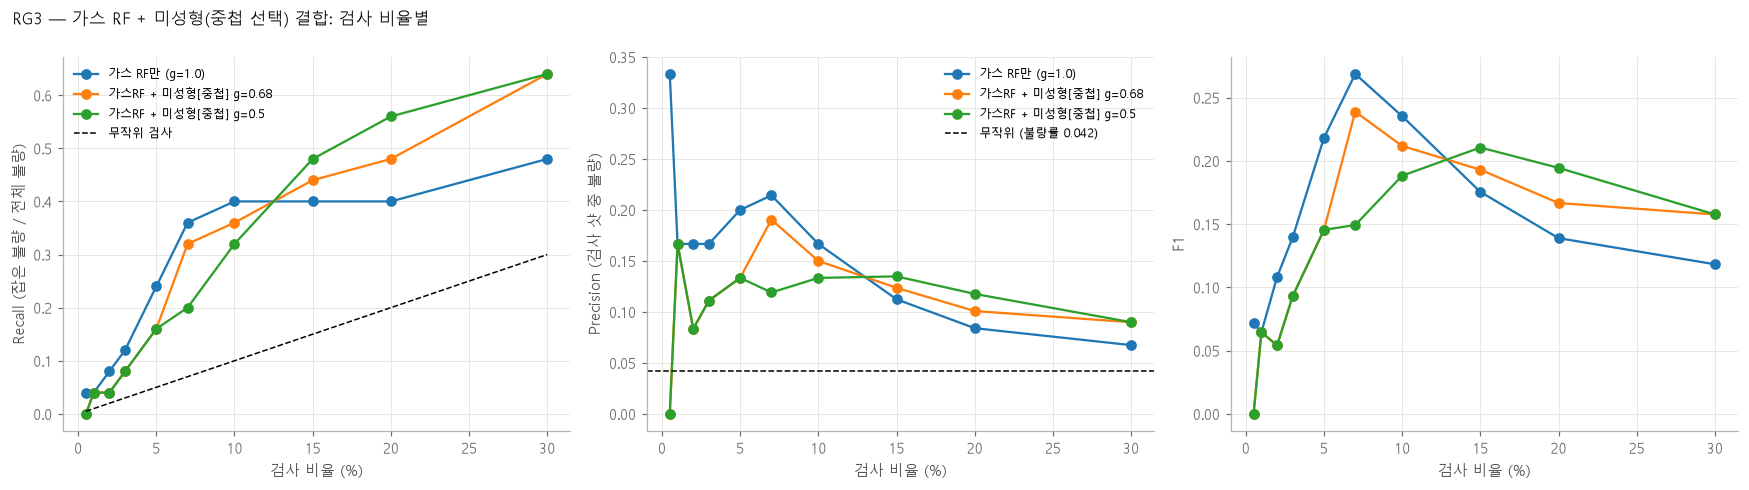

In [3]:
# 그래프: 가스 RF만 vs 결합(중첩, g=0.68·0.5)
sub = {k: v for k, v in T.items() if k.startswith('가스 RF만') or '중첩' in k}
IC.plot_curves(sub, 'RG3 — 가스 RF + 미성형(중첩 선택) 결합: 검사 비율별', save='./outputs/inspect_curve/rg3_combo.png')
pd.concat(T.values()).to_csv('./outputs/inspect_curve/rg3_combo.csv', index=False, encoding='utf-8-sig')